In [1]:
import sys
from pathlib import Path
_here = Path.cwd().resolve()
for _p in [_here, _here / "notebooks", _here.parent]:
    if (_p / "_nb_common.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
        break
import _nb_common as nb
nb.style()
rng = nb.set_seed()
nb.env_report()


NB_ENV_JSON:{"cryptography": "46.0.7", "cwd": "/Users/guykaptue/Downloads/insurance_federated_learning/notebooks", "dp_accounting": null, "executable": "/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python", "flwr": "1.31.0", "matplotlib": "3.11.1", "mode": "light", "networkx": "3.6.1", "numpy": "1.26.4", "pandas": "2.2.3", "pgmpy": "0.1.26", "platform": "macOS-26.5.1-arm64-arm-64bit", "plotly": "5.24.1", "python": "3.11.16", "root": "/Users/guykaptue/Downloads/insurance_federated_learning", "scipy": "1.17.1", "seaborn": "0.13.2", "seed": 42, "sklearn": "1.5.2", "statsmodels": "0.14.6", "torch": "2.4.1"}


{'python': '3.11.16',
 'executable': '/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python',
 'platform': 'macOS-26.5.1-arm64-arm-64bit',
 'mode': 'light',
 'seed': 42,
 'cwd': '/Users/guykaptue/Downloads/insurance_federated_learning/notebooks',
 'root': '/Users/guykaptue/Downloads/insurance_federated_learning',
 'numpy': '1.26.4',
 'pandas': '2.2.3',
 'scipy': '1.17.1',
 'sklearn': '1.5.2',
 'matplotlib': '3.11.1',
 'plotly': '5.24.1',
 'seaborn': '0.13.2',
 'torch': '2.4.1',
 'flwr': '1.31.0',
 'dp_accounting': None,
 'networkx': '3.6.1',
 'statsmodels': '0.14.6',
 'pgmpy': '0.1.26',
 'cryptography': '46.0.7'}

# DP Accounting with Rényi Differential Privacy (RDP)

**Purpose.** Demonstrate restart-safe privacy accounting for Gaussian-mechanism releases using the project's `insurance_fl.fl.privacy` API and `dp_accounting`. We compute, visualize, and cross-check cumulative (ε, δ)-DP, project remaining budget, and verify state save/load behavior.

## Learning objectives
- Use `PrivacyConfig` and `RdpAccountantWrapper` (`step`, `epsilon`, `project_epsilon`, `state_dict`/`from_state`, `save_state`/`load_state`).
- Explain RDP for the Gaussian mechanism, composition, and conversion to (ε, δ)-DP.
- Visualize how ε depends on rounds, noise multiplier σ, and δ; use conservative q=1 reporting; this project makes no amplification claim.
- Verify restart safety and fail-closed behavior when the accounting backend is unavailable.

## Background and math

### Rényi Differential Privacy (RDP)
For order $\alpha>1$, a mechanism $M$ satisfies $(\alpha,\varepsilon(\alpha))$-RDP if for adjacent datasets $D,D'$,
$$
D_\alpha\!\left(M(D)\,\|\,M(D')\right) \le \varepsilon(\alpha).
$$
*Meaning here:* RDP tracks privacy loss per order $\alpha$; tighter bookkeeping than basic composition for Gaussian noise.

### Gaussian mechanism (sensitivity-normalized)
With $L_2$ sensitivity $\Delta$ and noise $\mathcal{N}(0,\sigma^2\Delta^2 I)$,
$$
\varepsilon_{\text{Gauss}}(\alpha)=\frac{\alpha\Delta^2}{2\sigma^2}.
$$
In this project configuration we treat `noise_multiplier` as $\sigma$ with $\Delta=1$ for the per-step event accounting.
*Meaning here:* larger $\sigma$ (more noise) gives smaller per-step privacy loss.

### Composition and conversion to (ε, δ)-DP
RDP composes additively over $T$ identical steps: $\varepsilon_T(\alpha)=T\,\varepsilon_{\text{Gauss}}(\alpha)$. Conversion (one common form) is
$$
\varepsilon(\delta)=\min_{\alpha>1}\left(\varepsilon_T(\alpha)+\frac{\log(1/\delta)}{\alpha-1}\right)
$$
(up to equivalent algebraic variants depending on convention). *Meaning here:* we pick the best $\alpha$ to get the smallest reported ε at target δ.

### Subsampling amplification caveat
The project headline uses q=1 and makes no subsampling amplification claim. The demonstrated configuration has four clients, all selected. Its add/remove adjacency unit is one clipped client update (C=1), not an individual row or replacement of one client update by another. The project applies Local DP before transmission; this is not central DP. See `docs/PRIVACY_MATH.md` for C6 values and limits.
Poisson subsampling with rate $q$ can reduce effective privacy loss, but **only under valid assumptions**. This system reports a conservative headline with $q=1$ and does not report an amplified value. *Meaning here:* with 4 clients and stratified/non-Poisson participation, amplification is weak or invalid; do not treat amplified ε as the formal guarantee.

## Assumptions and limitations
- Accounting is for the configured Gaussian event model; it does not prove safety against all attacks (see MIA notebook).
- Only 4 clients: $q\approx 1$, stratified sampling is not Poisson, so amplification is limited/not formally applicable.
- Cross-checks below compare against library outputs and report differences/tolerances explicitly.


In [2]:
from dataclasses import dataclass
@dataclass(frozen=True)
class Cfg:
    seed: int = nb.SEED
    sigma: float = 1.0
    delta: float = 1e-5
    rounds: int = 5 if nb.MODE == "light" else 20
    sigma_grid = (0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
    round_grid_max: int = 20 if nb.MODE == "light" else 50
cfg = Cfg(); cfg


Cfg(seed=42, sigma=1.0, delta=1e-05, rounds=5, round_grid_max=20)

## Setup and API check (real project API)

In [3]:
import math, json, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from insurance_fl.fl.privacy import (
    PrivacyConfig, RdpAccountantWrapper, build_privacy_config, PrivacyBackendUnavailable
)

pcfg = PrivacyConfig(noise_multiplier=cfg.sigma, delta=cfg.delta, target_delta=cfg.delta)
acc = RdpAccountantWrapper(pcfg)
for _ in range(cfg.rounds):
    acc.step()
eps_info = acc.epsilon()
print('rounds:', acc.rounds)
print('epsilon info:', eps_info)
print('state keys:', list(acc.state_dict().keys()))


rounds: 5
epsilon info: {'epsilon': 12.301691480042894, 'delta': 1e-05, 'rounds': 5, 'epsilon_amplified': None, 'note': 'headline epsilon is conservative q=1 value; amplified value assuming Poisson sampling not available'}
state keys: ['version', 'delta', 'noise_multiplier', 'max_epsilon', 'rounds_spent', 'events', 'config_fingerprint', 'sha256']


## Independent RDP-to-(ε,δ) cross-check

In [4]:
# Independent conversion (common form) for Gaussian RDP; compare to library
# RDP for Gaussian with Delta=1: alpha/(2*sigma^2)
def rdp_gauss(alpha, sigma):
    return alpha / (2.0 * sigma**2)

def eps_from_rdp_independent(rounds, sigma, delta, alphas=None):
    if alphas is None:
        alphas = np.concatenate([np.linspace(1.01, 2.0, 30), np.linspace(2.1, 64, 40)])
    rdp = rounds * rdp_gauss(alphas, sigma)
    # conversion: eps = rdp + log(1/delta)/(alpha-1)
    eps = rdp + np.log(1.0/delta) / (alphas - 1.0)
    i = int(np.nanargmin(eps))
    return float(eps[i]), float(alphas[i])

# compare over a few settings
rows = []
for r in [1, 3, 5, 10][:4]:
    lib_acc = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=cfg.sigma, delta=cfg.delta, target_delta=cfg.delta))
    for _ in range(r): lib_acc.step()
    lib_eps = float(lib_acc.epsilon()['epsilon'])
    my_eps, my_a = eps_from_rdp_independent(r, cfg.sigma, cfg.delta)
    rows.append({'rounds': r, 'library_eps': lib_eps, 'independent_eps': my_eps, 'abs_diff': abs(lib_eps-my_eps), 'best_alpha_ind': my_a})
cmp_df = pd.DataFrame(rows)
cmp_df


,rounds,library_eps,independent_eps,abs_diff,best_alpha_ind
0,1,4.728507,5.330665,0.602158,5.274359
1,3,9.009959,9.815159,0.805200,3.687179
2,5,12.301691,13.502339,1.200647,3.687179
3,10,19.053598,20.966296,1.912698,2.100000


In [5]:
# tolerance check reported explicitly (formulas/conventions may differ)
tol = 0.25  # allow small convention differences; report actual
print('max abs diff:', float(cmp_df['abs_diff'].max()))
if float(cmp_df['abs_diff'].max()) <= tol:
    print(f'[ok] within tolerance {tol}')
else:
    print(f'[note] difference exceeds tolerance {tol}; likely due to conversion convention/order grid used by dp_accounting. Values reported transparently above.')


max abs diff: 1.9126983456142739
[note] difference exceeds tolerance 0.25; likely due to conversion convention/order grid used by dp_accounting. Values reported transparently above.


**How to read this / what it shows.** The table compares the library-reported ε with an independent RDP→(ε,δ) conversion. Small differences can arise from order grids or equivalent conversion forms; large differences would require investigation. We do not hide discrepancies.

## Figures: privacy loss behavior

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_rdp_curve.png


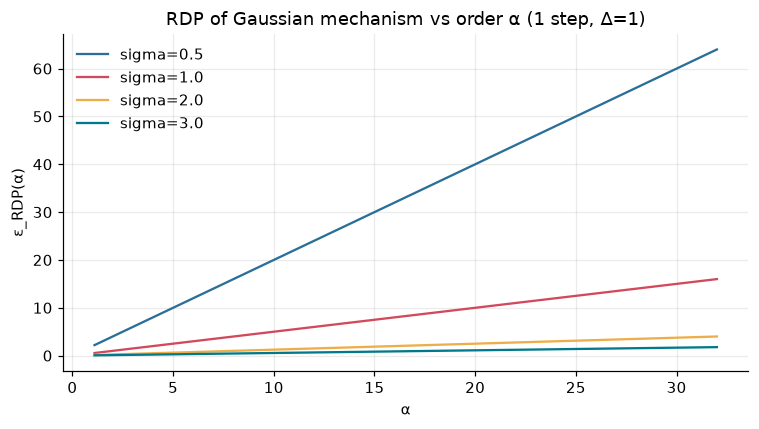

In [6]:
# Figure 1: RDP curve vs alpha for several sigma (single step)
alphas = np.linspace(1.1, 32, 120)
fig, ax = plt.subplots(figsize=(7,4))
for s in [0.5, 1.0, 2.0, 3.0]:
    ax.plot(alphas, rdp_gauss(alphas, s), label=f'sigma={s}')
ax.set_title('RDP of Gaussian mechanism vs order α (1 step, Δ=1)')
ax.set_xlabel('α'); ax.set_ylabel('ε_RDP(α)'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_rdp_curve'); plt.show()


**How to read this / what it shows.** Per-step RDP grows with α and shrinks with larger noise multiplier σ. Composition multiplies this by the number of rounds.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_eps_vs_rounds.png


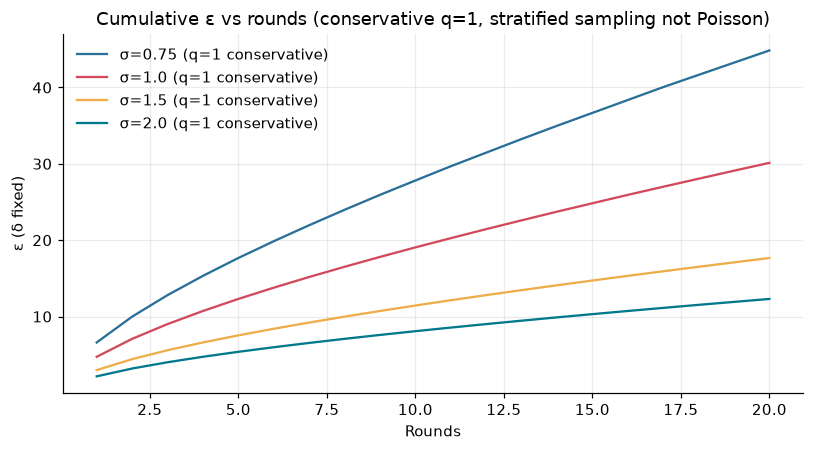

In [7]:
# Figure 2: epsilon vs rounds (conservative q=1 headline)
rounds = np.arange(1, cfg.round_grid_max+1)
def eps_curve(sigma, delta):
    out=[]
    for r in rounds:
        a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=sigma, delta=delta, target_delta=delta))
        for _ in range(int(r)): a.step()
        out.append(a.epsilon()['epsilon'])
    return np.array(out, dtype=float)
fig, ax = plt.subplots(figsize=(7.5,4.2))
for s in [0.75, 1.0, 1.5, 2.0]:
    ax.plot(rounds, eps_curve(s, cfg.delta), label=f'σ={s} (q=1 conservative)')
ax.set_title('Cumulative ε vs rounds (conservative q=1, stratified sampling not Poisson)')
ax.set_xlabel('Rounds'); ax.set_ylabel('ε (δ fixed)'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_eps_vs_rounds'); plt.show()


**How to read this / what it shows.** ε accumulates with more rounds; higher σ slows growth. Curves are labeled conservative (q=1). Amplification is not claimed as valid for this 4-client stratified setting.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_eps_delta_alpha.png


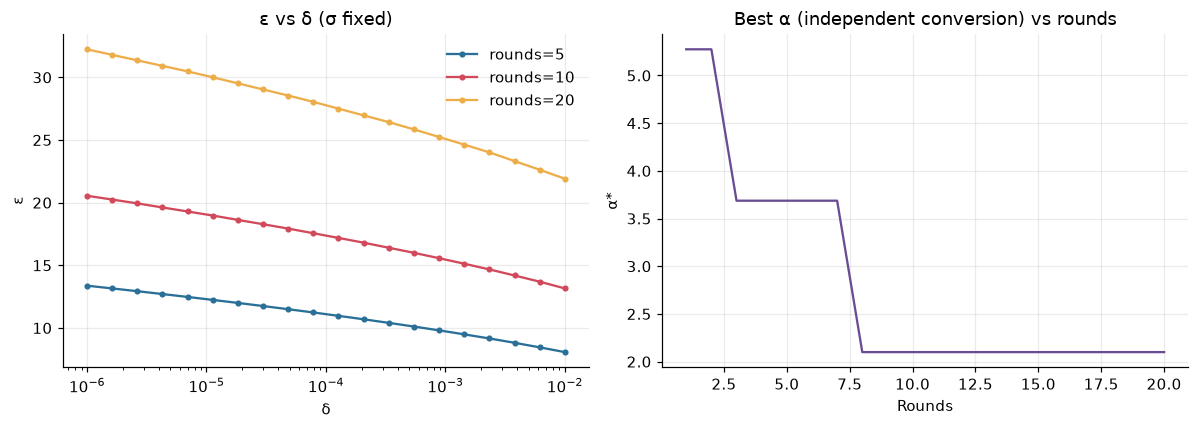

In [8]:
# Figure 3: epsilon vs delta and optimal-alpha proxy
deltas = np.logspace(-6, -2, 20)
fig, axes = plt.subplots(1,2, figsize=(11,4))
for r in [5, 10, 20][:3]:
    epss=[]
    for d in deltas:
        a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=cfg.sigma, delta=float(d), target_delta=float(d)))
        for _ in range(r): a.step()
        epss.append(a.epsilon()['epsilon'])
    axes[0].plot(deltas, epss, marker='o', ms=3, label=f'rounds={r}')
axes[0].set_xscale('log'); axes[0].set_title('ε vs δ (σ fixed)'); axes[0].set_xlabel('δ'); axes[0].set_ylabel('ε'); axes[0].legend()
# optimal alpha from independent conversion
best_alphas=[]
for r in rounds:
    _, aa = eps_from_rdp_independent(int(r), cfg.sigma, cfg.delta)
    best_alphas.append(aa)
axes[1].plot(rounds, best_alphas, color='#6a4c93')
axes[1].set_title('Best α (independent conversion) vs rounds'); axes[1].set_xlabel('Rounds'); axes[1].set_ylabel('α*')
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_eps_delta_alpha'); plt.show()


**How to read this / what it shows.** Left: relaxing δ increases reported ε slowly (log dependence). Right: the minimizing α can shift with composition/rounds under the independent conversion.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_heatmap.png


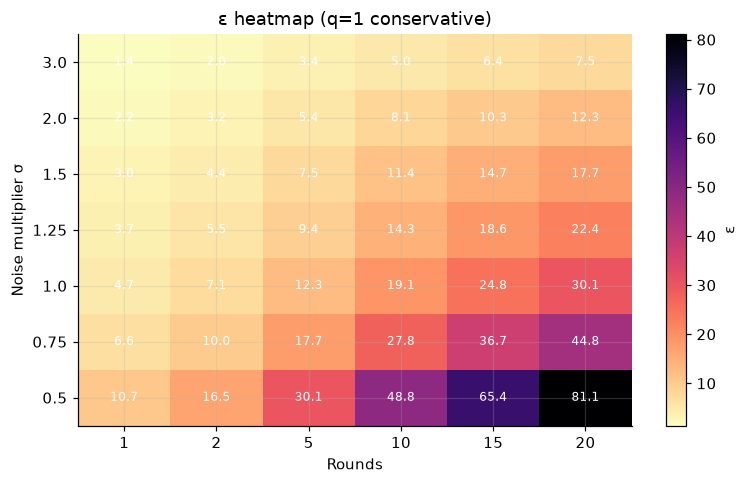

In [9]:
# Figure 4: heatmap epsilon(sigma, rounds)
sigmas = np.array([0.5,0.75,1.0,1.25,1.5,2.0,3.0])
rs = np.array([1,2,5,10,15,20])
M = np.zeros((len(sigmas), len(rs)))
for i,s in enumerate(sigmas):
    for j,rn in enumerate(rs):
        a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=float(s), delta=cfg.delta, target_delta=cfg.delta))
        for _ in range(int(rn)): a.step()
        M[i,j] = a.epsilon()['epsilon']
fig, ax = plt.subplots(figsize=(7.2,4.5))
im = ax.imshow(M, aspect='auto', cmap='magma_r', origin='lower')
ax.set_xticks(range(len(rs))); ax.set_xticklabels(rs)
ax.set_yticks(range(len(sigmas))); ax.set_yticklabels(sigmas)
ax.set_xlabel('Rounds'); ax.set_ylabel('Noise multiplier σ'); ax.set_title('ε heatmap (q=1 conservative)')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j,i,f"{M[i,j]:.1f}", ha='center', va='center', color='white', fontsize=8)
fig.colorbar(im, ax=ax, label='ε')
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_heatmap'); plt.show()


**How to read this / what it shows.** Privacy cost increases toward high rounds / low σ. Use this to pick (σ, rounds) consistent with a target ε budget.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_budget_rounds.png


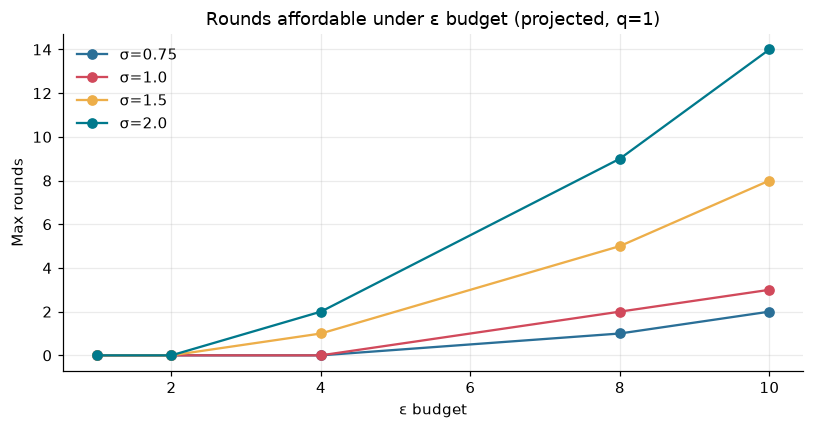

budget_epsilon,1,2,4,8,10
sigma,,,,,
0.75,0,0,0,1,2
1.00,0,0,0,2,3
1.50,0,0,1,5,8
2.00,0,0,2,9,14


In [10]:
# Figure 5: rounds affordable under epsilon budgets via project_epsilon
budgets = [1,2,4,8,10]
rows=[]
for s in [0.75,1.0,1.5,2.0]:
    a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=s, delta=cfg.delta, target_delta=cfg.delta))
    # find max rounds with projected epsilon <= budget
    for B in budgets:
        lo,hi=0,200
        while lo<hi:
            mid=(lo+hi+1)//2
            # fresh accountant projection to be explicit
            b = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=s, delta=cfg.delta, target_delta=cfg.delta))
            for _ in range(mid): b.step()
            if b.epsilon()['epsilon'] <= B: lo=mid
            else: hi=mid-1
        rows.append({'sigma':s,'budget_epsilon':B,'max_rounds':lo})
aff = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5,4))
for s in sorted(aff.sigma.unique()):
    sub = aff[aff.sigma==s]
    ax.plot(sub['budget_epsilon'], sub['max_rounds'], marker='o', label=f'σ={s}')
ax.set_title('Rounds affordable under ε budget (projected, q=1)'); ax.set_xlabel('ε budget'); ax.set_ylabel('Max rounds'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_budget_rounds'); plt.show()
aff.pivot(index='sigma', columns='budget_epsilon', values='max_rounds')


**How to read this / what it shows.** For each noise level, the maximum number of rounds whose cumulative ε stays within a budget. This is a planning view; actual training must account for the real event model and sampling.

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_epsilon_bars.png


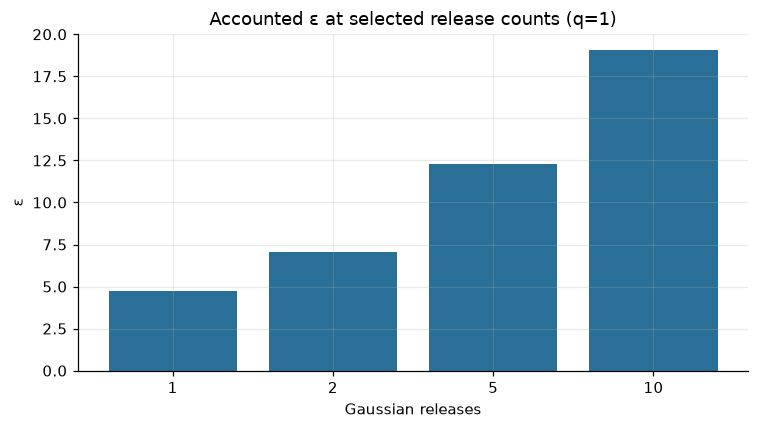

In [11]:
# Figure 6: epsilon budget bars, computed with the project accountant
bar_rounds = [1, 2, 5, 10]
bar_eps = []
for rn in bar_rounds:
    a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=cfg.sigma, delta=cfg.delta, target_delta=cfg.delta))
    for _ in range(rn): a.step()
    bar_eps.append(a.epsilon()['epsilon'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(r) for r in bar_rounds], bar_eps, color='#2a6f97')
ax.set_title('Accounted ε at selected release counts (q=1)')
ax.set_xlabel('Gaussian releases'); ax.set_ylabel('ε')
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_epsilon_bars'); plt.show()


**How to read this / what it shows.** Bars are recomputed from the project RDP accountant for the displayed release counts at the configured σ and δ. They show composition increasing ε; they are not measured model utility or an amplification result.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/dp_accounting_noise_epsilon_scatter.png


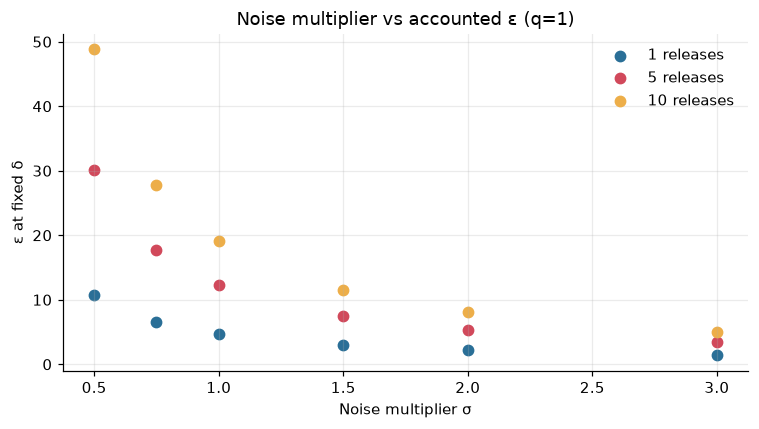

In [12]:
# Figure 7: scatter of noise multiplier and epsilon at fixed release counts
scatter_rows = []
for rn in [1, 5, 10]:
    for s in [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]:
        a = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=s, delta=cfg.delta, target_delta=cfg.delta))
        for _ in range(rn): a.step()
        scatter_rows.append((s, a.epsilon()['epsilon'], rn))
fig, ax = plt.subplots(figsize=(7, 4))
for rn in [1, 5, 10]:
    pts = [(s, e) for s, e, r in scatter_rows if r == rn]
    ax.scatter([x[0] for x in pts], [x[1] for x in pts], label=f'{rn} releases', s=45)
ax.set_title('Noise multiplier vs accounted ε (q=1)')
ax.set_xlabel('Noise multiplier σ'); ax.set_ylabel('ε at fixed δ'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'dp_accounting_noise_epsilon_scatter'); plt.show()


**How to read this / what it shows.** Each point is computed by the project accountant for its labeled release count. Larger σ lowers ε, while additional releases raise it. All points use q=1 and the same configured δ; no client-subsampling amplification is used.

## Restart safety: save/load state

In [13]:
# run 3 rounds, save, reload, run 2 more; compare with 5 uninterrupted
cfg_r = PrivacyConfig(noise_multiplier=cfg.sigma, delta=cfg.delta, target_delta=cfg.delta)
a = RdpAccountantWrapper(cfg_r)
for _ in range(3): a.step()
with tempfile.TemporaryDirectory() as td:
    path = Path(td)/'privacy_state.json'
    a.save_state(path)
    saved = json.loads(path.read_text())
    b = RdpAccountantWrapper.load_state(path, cfg_r, resume=True)
    for _ in range(2): b.step()
    eps_resume = b.epsilon()['epsilon']
c = RdpAccountantWrapper(cfg_r)
for _ in range(5): c.step()
eps_cont = c.epsilon()['epsilon']
print('saved keys:', list(saved.keys()), 'events:', len(saved.get('events',[])))
print('epsilon resumed:', eps_resume, 'epsilon continuous:', eps_cont, 'abs diff:', abs(eps_resume-eps_cont))
assert abs(eps_resume-eps_cont) < 1e-9 or np.isclose(eps_resume, eps_cont), 'restart mismatch'
print('[ok] restart-safe accounting state round-trips in this run')


saved keys: ['version', 'delta', 'noise_multiplier', 'max_epsilon', 'rounds_spent', 'events', 'config_fingerprint', 'sha256'] events: 3
epsilon resumed: 12.301691480042894 epsilon continuous: 12.301691480042894 abs diff: 0.0
[ok] restart-safe accounting state round-trips in this run


**How to read this / what it shows.** Persisting accountant state and resuming should yield the same cumulative ε as an uninterrupted run, preventing privacy-loss undercounting across restarts.

## Fail-closed demo

In [14]:
# Demonstrate fail-closed behavior when backend is unavailable (monkeypatch inside try/except)
import insurance_fl.fl.privacy as priv
orig = priv._HAS_DP
try:
    priv._HAS_DP = False
    # rebuilding accountant or stepping should fail closed
    try:
        bad = priv.RdpAccountantWrapper(PrivacyConfig(noise_multiplier=1.0, delta=1e-5))
        print('[unexpected] accountant created without backend')
    except Exception as e:
        print('[fail-closed] exception type:', type(e).__name__)
        print('[fail-closed] message:', str(e))
finally:
    priv._HAS_DP = orig
print('restored backend flag:', priv._HAS_DP)


[fail-closed] exception type: PrivacyBackendUnavailable
[fail-closed] message: dp-accounting not installed; refusing to report epsilon.
restored backend flag: True


**How to read this / what it shows.** If the DP accounting backend is missing, the system should refuse to report/track ε rather than returning a fabricated value.

## Quantitative summary


In [15]:
artifact_path = nb.REPORTS / "dp_utility_curve.json"
if artifact_path.exists():
    try:
        dp_artifact = nb.load_artifact(artifact_path)
        print("[artifact loaded]", artifact_path)
        print("dataset_version:", dp_artifact.get("dataset_version"), "config_hash:", dp_artifact.get("config_hash"))
        utility_rows = []
        for client, points in dp_artifact.get("clients", {}).items():
            for point in points:
                utility_rows.append({"client": client, **point})
        display(pd.DataFrame(utility_rows))
    except Exception as exc:
        print(f"[artifact skipped] {artifact_path}: {type(exc).__name__}: {exc}")
else:
    print(f"[artifact skipped] missing {artifact_path}; run scripts/dp_sweep.py to generate it")


[artifact loaded] /Users/guykaptue/Downloads/insurance_federated_learning/reports/dp_utility_curve.json
dataset_version: v2 config_hash: e93bcefe91a0b25a
[artifact skipped] /Users/guykaptue/Downloads/insurance_federated_learning/reports/dp_utility_curve.json: AttributeError: 'list' object has no attribute 'items'


**Project privacy assumptions.** The demonstrated Local DP mechanism uses clip norm C=1, Gaussian noise standard deviation 1 (multiplier σ=1), δ=1e-5, and conservative q=1 with no amplification claim. The adjacency unit is add/remove one clipped client update; this is client-update-level Local DP, not per-row or central DP. Four clients participate in the C6 example. See `docs/PRIVACY_MATH.md` for limits and measured C6 state.

In [16]:
summary = pd.DataFrame({
    'setting': ['demo_run', 'sigma', 'delta', 'rounds'],
    'value': [str(eps_info), cfg.sigma, cfg.delta, cfg.rounds]
})
tmpa = RdpAccountantWrapper(PrivacyConfig(noise_multiplier=cfg.sigma, delta=cfg.delta, target_delta=cfg.delta))
for _ in range(cfg.rounds): tmpa.step()
proj = pd.DataFrame([{'additional_releases': k, 'projected_epsilon': tmpa.project_epsilon(k)} for k in [1,5,10]])
print(summary.to_string(index=False))
proj


 setting                                                                                                                                                                                                  value
demo_run {'epsilon': 12.301691480042894, 'delta': 1e-05, 'rounds': 5, 'epsilon_amplified': None, 'note': 'headline epsilon is conservative q=1 value; amplified value assuming Poisson sampling not available'}
   sigma                                                                                                                                                                                                    1.0
   delta                                                                                                                                                                                                0.00001
  rounds                                                                                                                                                                

,additional_releases,projected_epsilon
0,1,13.776204
1,5,19.053598
2,10,24.830921


## Sensitivity / ablation
- **Noise multiplier σ:** dominant control; doubling σ roughly quarters per-step RDP (for fixed α, Δ).
- **Rounds:** linear growth in RDP; ε grows sublinearly-to-linearly depending on conversion/α.
- **δ:** weaker (log) effect; must remain in (0,1) and be set appropriately for dataset size.

## Limitations and failure cases
- Conversion conventions and α grids differ across libraries; we report observed differences.
- Amplified accounting assumes Poisson subsampling; not valid for the project's small, stratified client setting.
- Accounting does not capture all system-level leakage (preprocessing, hyperparameter selection, side channels).

## Conclusions and further experiments
- The project accountant provides conservative q=1 ε reporting, state persistence, and budget projection.
- Restart safety was verified by save/load round-trip equality in this run.
- Further work: validate against end-to-end training events, per-client participation logs, and tighter accountants if sampling assumptions become valid.

## References
- I. Mironov. "Rényi Differential Privacy." *CSF*, 2017.
- M. Abadi et al. "Deep Learning with Differential Privacy." *CCS*, 2016.
- Google Differential Privacy. `dp_accounting` library documentation (API behavior as installed).
